Found 5 files: ['ChatGPT_Pak_2022.csv', 'ChatGPT_Pak_2023.csv', 'ChatGPT_Pak_2024.csv', 'ChatGPT_Pak_2025.csv', 'ChatGPT_Pak_2026.csv']
ChatGPT_Pak_2022.csv           -> rows=  4 | 2022-12-04 to 2022-12-25 | Google sum=366
ChatGPT_Pak_2023.csv           -> rows= 54 | 2022-12-25 to 2023-12-31 | Google sum=4750
ChatGPT_Pak_2024.csv           -> rows= 53 | 2023-12-31 to 2024-12-29 | Google sum=4806
ChatGPT_Pak_2025.csv           -> rows= 53 | 2024-12-29 to 2025-12-28 | Google sum=4177
ChatGPT_Pak_2026.csv           -> rows= 47 | 2025-12-28 to 2026-11-15 | Google sum=4017

Reference anchor volume (Google sum): 4806
File 1 (2022): scale factor = 13.1311
File 2 (2022): scale factor = 1.0118
File 3 (2023): scale factor = 1.0000
File 4 (2024): scale factor = 1.1506
File 5 (2025): scale factor = 1.1964

Dropped 4 duplicate week(s) at chunk boundaries.
After trimming pre-launch: 207 weeks (2022-12-04 to 2026-11-15)
Peak scaled value = 118.45, normalized to 100


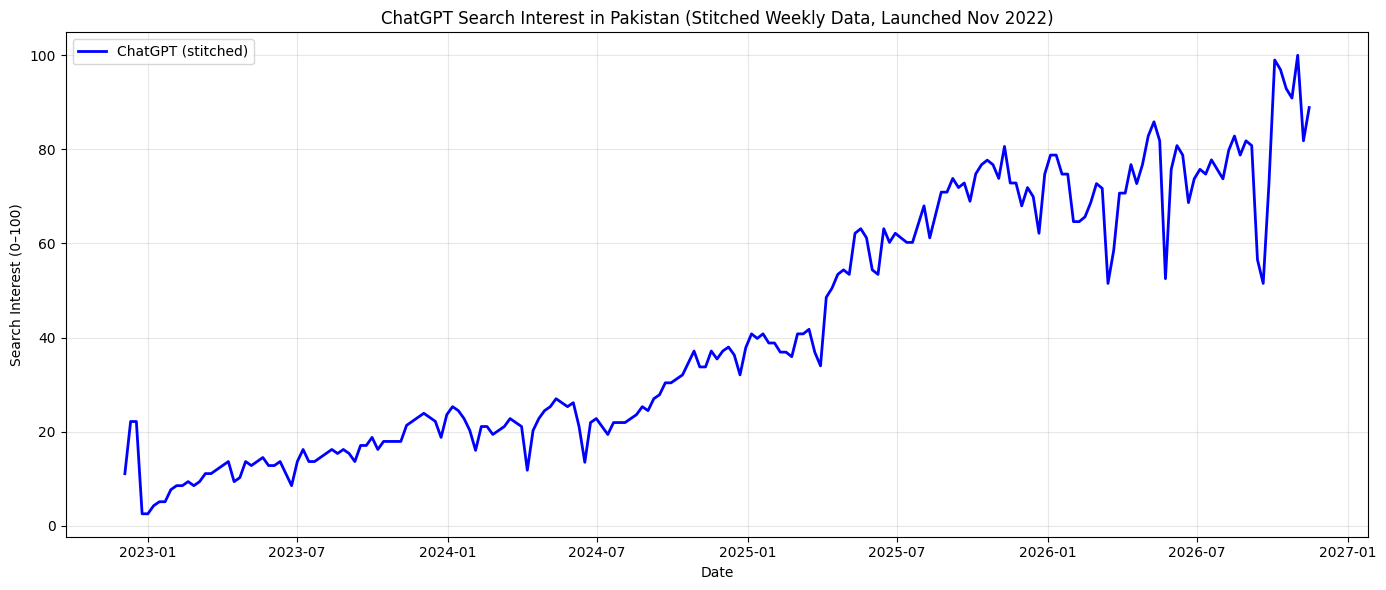

Saved clean dataset to ChatGPT_PK_Final.csv


In [ ]:
import pandas as pd
import glob
import matplotlib.pyplot as plt

# ============================================================
# 1. Load all CSV files dynamically
# ============================================================
files = sorted(glob.glob('*.csv'))
print(f"Found {len(files)} files: {files}")

dfs = []
for file in files:
    # Do NOT use skiprows — files start with the real header
    # 'Time, ChatGPT, Google'.
    df = pd.read_csv(file, encoding='utf-8-sig')

    # Strip ' : (Pakistan)' style suffixes
    df.columns = [str(col).split(':')[0].strip() for col in df.columns]

    # First column is the date -> rename to 'Week'
    df = df.rename(columns={df.columns[0]: 'Week'})
    df['Week'] = pd.to_datetime(df['Week'])

    # Robust column mapping
    rename_map = {}
    for c in df.columns:
        cl = str(c).lower()
        if 'chatgpt' in cl:
            rename_map[c] = 'ChatGPT'
        elif 'google' in cl:
            rename_map[c] = 'Google'
    df = df.rename(columns=rename_map)

    missing = [c for c in ('ChatGPT', 'Google') if c not in df.columns]
    if missing:
        raise KeyError(
            f"{file} is missing columns {missing}. "
            f"Got columns: {df.columns.tolist()}"
        )

    df = df[['Week', 'ChatGPT', 'Google']]

    print(f"{file:30s} -> rows={len(df):3d} | "
          f"{df['Week'].min().date()} to {df['Week'].max().date()} | "
          f"Google sum={df['Google'].sum():.0f}")

    dfs.append(df)

# ============================================================
# 2. Find the reference anchor (largest Google total)
# ============================================================
anchor_sums = [df['Google'].sum() for df in dfs]
reference_anchor_sum = max(anchor_sums)
print(f"\nReference anchor volume (Google sum): {reference_anchor_sum:.0f}")

# ============================================================
# 3. Scale each chunk, tagging source order
# ============================================================
scaled_dfs = []
for i, df in enumerate(dfs):
    current_anchor_sum = df['Google'].sum()

    if current_anchor_sum == 0:
        print(f"WARNING: {files[i]} has Google sum = 0, skipping.")
        continue

    factor = reference_anchor_sum / current_anchor_sum
    print(f"File {i+1} ({df['Week'].min().year}): scale factor = {factor:.4f}")

    df = df.copy()
    df['ChatGPT_Scaled'] = df['ChatGPT'] * factor
    df['_chunk'] = i                    # 0=oldest … N=newest (for dedup tie-break)
    scaled_dfs.append(df)

# ============================================================
# 4. Merge, sort, and drop duplicate weeks
# ============================================================
final_df = pd.concat(scaled_dfs, ignore_index=True)

# Sort by Week first, then by chunk index. For rows sharing the same
# Week (chunk boundaries), the newest chunk is now guaranteed to be last.
final_df = final_df.sort_values(['Week', '_chunk']).reset_index(drop=True)

dup_before = len(final_df)
final_df = final_df.drop_duplicates(subset=['Week'], keep='last')
final_df = final_df.drop(columns='_chunk').reset_index(drop=True)
print(f"\nDropped {dup_before - len(final_df)} duplicate week(s) at chunk boundaries.")

# ============================================================
# 5. Delete pre-launch data
# ============================================================
launch_date = pd.Timestamp('2022-11-20')
final_df = final_df[final_df['Week'] >= launch_date].reset_index(drop=True)
print(f"After trimming pre-launch: {len(final_df)} weeks "
      f"({final_df['Week'].min().date()} to {final_df['Week'].max().date()})")

# ============================================================
# 6. Final renormalization (true peak = 100)
# ============================================================
true_peak = final_df['ChatGPT_Scaled'].max()
final_df['ChatGPT_Normalized'] = (final_df['ChatGPT_Scaled'] / true_peak) * 100
print(f"Peak scaled value = {true_peak:.2f}, normalized to 100")

# ============================================================
# 7. Plot
# ============================================================
plt.figure(figsize=(14, 6))
plt.plot(
    final_df['Week'],
    final_df['ChatGPT_Normalized'],
    label='ChatGPT (stitched)',
    color='blue',
    linewidth=2,
)
plt.title('ChatGPT Search Interest in Pakistan '
          '(Stitched Weekly Data, Launched Nov 2022)')
plt.xlabel('Date')
plt.ylabel('Search Interest (0–100)')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# ============================================================
# 8. Save clean dataset
# ============================================================
final_df[['Week', 'ChatGPT_Normalized']].to_csv(
    'ChatGPT_PK_Final.csv', index=False
)
print("Saved clean dataset to ChatGPT_PK_Final.csv")


Bass fitting failed: Optimal parameters not found: The maximum number of function evaluations is exceeded.

--- Gompertz Model ---
Parameters: [np.float64(144.3141), np.float64(3.4164), np.float64(0.0093)]
R-squared: 0.9188

--- Logistic Model ---
Parameters: [np.float64(96.7344), np.float64(0.0228), np.float64(121.3261)]
R-squared: 0.9266


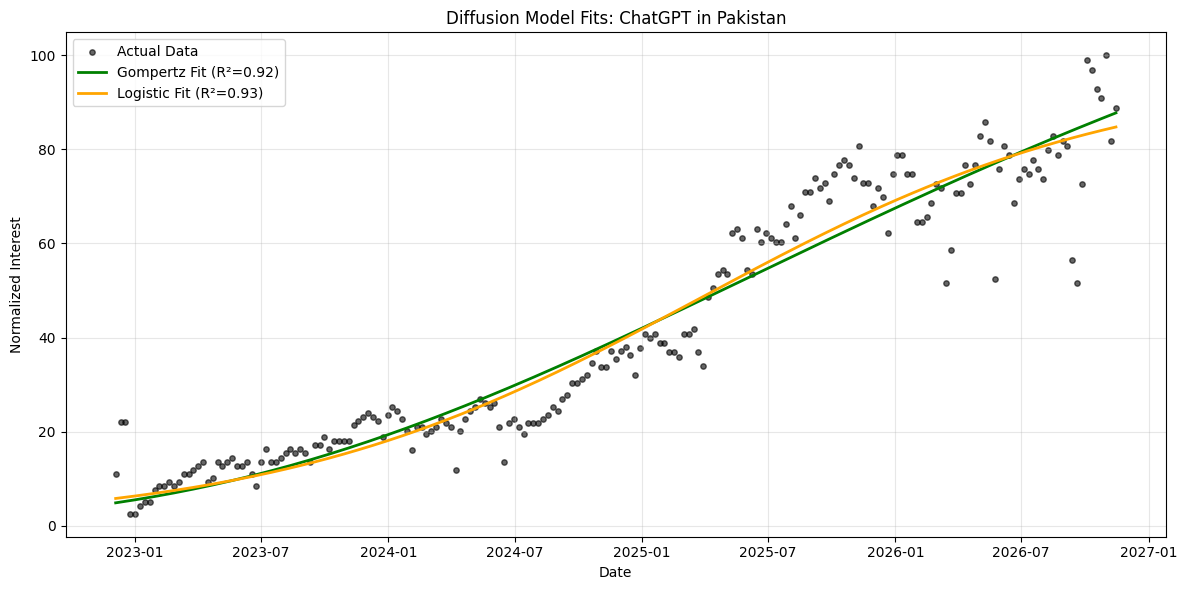

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# 1. Load your data
# (Ensure the file is in the same folder, or provide the full path)
df = pd.read_csv('ChatGPT_PK_Final.csv')
df['Week'] = pd.to_datetime(df['Week'])

# Trim the noisy first few weeks if desired (optional)
# df = df[df['Week'] >= '2023-01-01'].reset_index(drop=True)

# Create time variable (t = 1, 2, 3...)
df['t'] = range(1, len(df) + 1)
y = df['ChatGPT_Normalized'].values
t = df['t'].values

# ==========================================
# DEFINE THE THREE MODELS
# ==========================================
# 1. Bass Model (Non-cumulative PDF)
def bass_model(t, p, q, m):
    return m * ((p + q)**2 / p) * np.exp(-(p + q) * t) / ((1 + (q / p) * np.exp(-(p + q) * t))**2)

# 2. Gompertz Model
def gompertz_model(t, a, b, c):
    return a * np.exp(-b * np.exp(-c * t))

# 3. Logistic Model
def logistic_model(t, L, k, t0):
    return L / (1 + np.exp(-k * (t - t0)))

# ==========================================
# FIT THE MODELS (With robust guesses)
# ==========================================
models = {
    'Bass': {
        'func': bass_model,
        'p0': [0.01, 0.3, 150], # p, q, m (m is guessed higher than current peak)
        'bounds': ([0.0001, 0.001, 50], [0.5, 2.0, 1000])
    },
    'Gompertz': {
        'func': gompertz_model,
        'p0': [150, 5, 0.02], # a, b, c
        'bounds': ([50, 0.01, 0.001], [1000, 50, 0.5])
    },
    'Logistic': {
        'func': logistic_model,
        'p0': [150, 0.05, 100], # L, k, t0
        'bounds': ([50, 0.001, 1], [1000, 1.0, 300])
    }
}

plt.figure(figsize=(12, 6))
plt.scatter(df['Week'], y, label='Actual Data', color='black', s=15, alpha=0.6)

colors = {'Bass': 'red', 'Gompertz': 'green', 'Logistic': 'orange'}

for name, model_info in models.items():
    try:
        # maxfev=50000 gives the algorithm more time to find the answer
        popt, pcov = curve_fit(
            model_info['func'], t, y,
            p0=model_info['p0'],
            bounds=model_info['bounds'],
            maxfev=50000,
            method='trf' # Trust Region Reflective algorithm is more robust
        )

        # Calculate R-squared
        residuals = y - model_info['func'](t, *popt)
        ss_res = np.sum(residuals**2)
        ss_tot = np.sum((y - np.mean(y))**2)
        r_squared = 1 - (ss_res / ss_tot)

        print(f"\n--- {name} Model ---")
        print(f"Parameters: {[round(p, 4) for p in popt]}")
        print(f"R-squared: {r_squared:.4f}")

        # Plot the fitted curve
        plt.plot(df['Week'], model_info['func'](t, *popt), label=f'{name} Fit (R²={r_squared:.2f})', color=colors[name], linewidth=2)

    except Exception as e:
        print(f"\n{name} fitting failed: {e}")

plt.title('Diffusion Model Fits: ChatGPT in Pakistan')
plt.xlabel('Date')
plt.ylabel('Normalized Interest')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Found 4 files: ['ChatGPT_US_2023.csv', 'ChatGPT_US_2024.csv', 'ChatGPT_US_2025.csv', 'ChatGPT_US_2026.csv']
ChatGPT_US_2023.csv            -> rows= 54 | 2022-12-25 to 2023-12-31 | Google sum=4397
ChatGPT_US_2024.csv            -> rows= 53 | 2023-12-31 to 2024-12-29 | Google sum=4503
ChatGPT_US_2025.csv            -> rows= 53 | 2024-12-29 to 2025-12-28 | Google sum=4081
ChatGPT_US_2026.csv            -> rows= 47 | 2025-12-28 to 2026-11-15 | Google sum=3965

Reference anchor volume (Google sum): 4503
File 1 (2022): scale factor = 1.0241
File 2 (2023): scale factor = 1.0000
File 3 (2024): scale factor = 1.1034
File 4 (2025): scale factor = 1.1357

Dropped 3 duplicate week(s) at chunk boundaries.
After trimming pre-launch: 204 weeks (2022-12-25 to 2026-11-15)
Peak scaled value = 32.00, normalized to 100


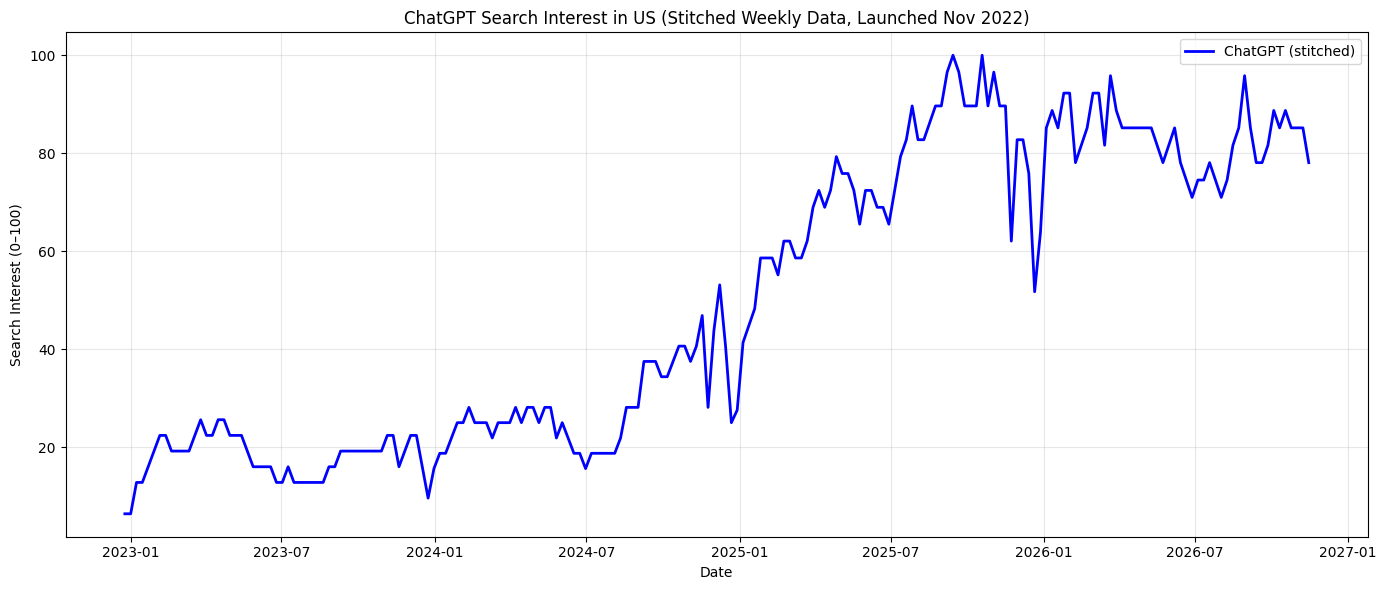

Saved clean dataset to ChatGPT_US_Final.csv


In [ ]:
import pandas as pd
import glob
import matplotlib.pyplot as plt

# ============================================================
# 1. Load all CSV files dynamically
# ============================================================
files = sorted(glob.glob('*.csv'))
print(f"Found {len(files)} files: {files}")

dfs = []
for file in files:
    # Do NOT use skiprows — files start with the real header
    # 'Time, ChatGPT, Google'.
    df = pd.read_csv(file, encoding='utf-8-sig')

    # Strip ' : (Pakistan)' style suffixes
    df.columns = [str(col).split(':')[0].strip() for col in df.columns]

    # First column is the date -> rename to 'Week'
    df = df.rename(columns={df.columns[0]: 'Week'})
    df['Week'] = pd.to_datetime(df['Week'])

    # Robust column mapping
    rename_map = {}
    for c in df.columns:
        cl = str(c).lower()
        if 'chatgpt' in cl:
            rename_map[c] = 'ChatGPT'
        elif 'google' in cl:
            rename_map[c] = 'Google'
    df = df.rename(columns=rename_map)

    missing = [c for c in ('ChatGPT', 'Google') if c not in df.columns]
    if missing:
        raise KeyError(
            f"{file} is missing columns {missing}. "
            f"Got columns: {df.columns.tolist()}"
        )

    df = df[['Week', 'ChatGPT', 'Google']]

    print(f"{file:30s} -> rows={len(df):3d} | "
          f"{df['Week'].min().date()} to {df['Week'].max().date()} | "
          f"Google sum={df['Google'].sum():.0f}")

    dfs.append(df)

# ============================================================
# 2. Find the reference anchor (largest Google total)
# ============================================================
anchor_sums = [df['Google'].sum() for df in dfs]
reference_anchor_sum = max(anchor_sums)
print(f"\nReference anchor volume (Google sum): {reference_anchor_sum:.0f}")

# ============================================================
# 3. Scale each chunk, tagging source order
# ============================================================
scaled_dfs = []
for i, df in enumerate(dfs):
    current_anchor_sum = df['Google'].sum()

    if current_anchor_sum == 0:
        print(f"WARNING: {files[i]} has Google sum = 0, skipping.")
        continue

    factor = reference_anchor_sum / current_anchor_sum
    print(f"File {i+1} ({df['Week'].min().year}): scale factor = {factor:.4f}")

    df = df.copy()
    df['ChatGPT_Scaled'] = df['ChatGPT'] * factor
    df['_chunk'] = i                    # 0=oldest … N=newest (for dedup tie-break)
    scaled_dfs.append(df)

# ============================================================
# 4. Merge, sort, and drop duplicate weeks
# ============================================================
final_df = pd.concat(scaled_dfs, ignore_index=True)

# Sort by Week first, then by chunk index. For rows sharing the same
# Week (chunk boundaries), the newest chunk is now guaranteed to be last.
final_df = final_df.sort_values(['Week', '_chunk']).reset_index(drop=True)

dup_before = len(final_df)
final_df = final_df.drop_duplicates(subset=['Week'], keep='last')
final_df = final_df.drop(columns='_chunk').reset_index(drop=True)
print(f"\nDropped {dup_before - len(final_df)} duplicate week(s) at chunk boundaries.")

# ============================================================
# 5. Delete pre-launch data
# ============================================================
launch_date = pd.Timestamp('2022-11-20')
final_df = final_df[final_df['Week'] >= launch_date].reset_index(drop=True)
print(f"After trimming pre-launch: {len(final_df)} weeks "
      f"({final_df['Week'].min().date()} to {final_df['Week'].max().date()})")

# ============================================================
# 6. Final renormalization (true peak = 100)
# ============================================================
true_peak = final_df['ChatGPT_Scaled'].max()
final_df['ChatGPT_Normalized'] = (final_df['ChatGPT_Scaled'] / true_peak) * 100
print(f"Peak scaled value = {true_peak:.2f}, normalized to 100")

# ============================================================
# 7. Plot
# ============================================================
plt.figure(figsize=(14, 6))
plt.plot(
    final_df['Week'],
    final_df['ChatGPT_Normalized'],
    label='ChatGPT (stitched)',
    color='blue',
    linewidth=2,
)
plt.title('ChatGPT Search Interest in US '
          '(Stitched Weekly Data, Launched Nov 2022)')
plt.xlabel('Date')
plt.ylabel('Search Interest (0–100)')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# ============================================================
# 8. Save clean dataset
# ============================================================
final_df[['Week', 'ChatGPT_Normalized']].to_csv(
    'ChatGPT_US_Final.csv', index=False
)
print("Saved clean dataset to ChatGPT_US_Final.csv")


--- Bass Model ---
Parameters: [np.float64(0.0001), np.float64(0.0423), np.float64(901.1599)]
R-squared: -2.1695

--- Gompertz Model ---
Parameters: [np.float64(114.0237), np.float64(3.4547), np.float64(0.014)]
R-squared: 0.8575

--- Logistic Model ---
Parameters: [np.float64(93.2224), np.float64(0.0307), np.float64(98.144)]
R-squared: 0.8824


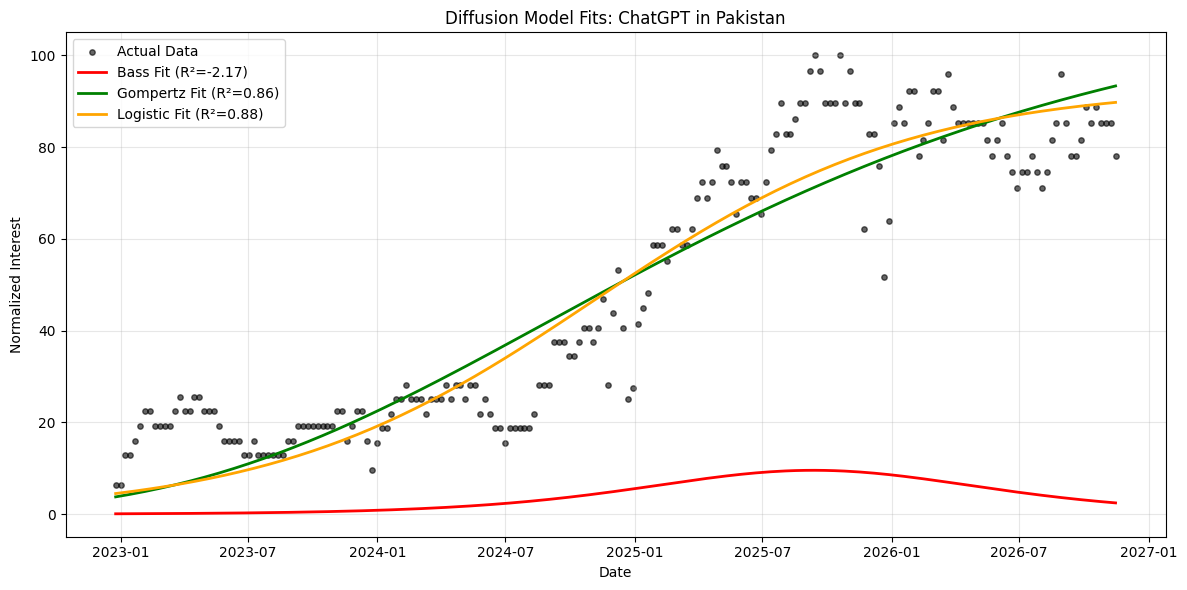

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# 1. Load your data
# (Ensure the file is in the same folder, or provide the full path)
df = pd.read_csv('ChatGPT_US_Final.csv')
df['Week'] = pd.to_datetime(df['Week'])

# Trim the noisy first few weeks if desired (optional)
# df = df[df['Week'] >= '2023-01-01'].reset_index(drop=True)

# Create time variable (t = 1, 2, 3...)
df['t'] = range(1, len(df) + 1)
y = df['ChatGPT_Normalized'].values
t = df['t'].values

# ==========================================
# DEFINE THE THREE MODELS
# ==========================================
# 1. Bass Model (Non-cumulative PDF)
def bass_model(t, p, q, m):
    return m * ((p + q)**2 / p) * np.exp(-(p + q) * t) / ((1 + (q / p) * np.exp(-(p + q) * t))**2)

# 2. Gompertz Model
def gompertz_model(t, a, b, c):
    return a * np.exp(-b * np.exp(-c * t))

# 3. Logistic Model
def logistic_model(t, L, k, t0):
    return L / (1 + np.exp(-k * (t - t0)))

# ==========================================
# FIT THE MODELS (With robust guesses)
# ==========================================
models = {
    'Bass': {
        'func': bass_model,
        'p0': [0.01, 0.3, 150], # p, q, m (m is guessed higher than current peak)
        'bounds': ([0.0001, 0.001, 50], [0.5, 2.0, 1000])
    },
    'Gompertz': {
        'func': gompertz_model,
        'p0': [150, 5, 0.02], # a, b, c
        'bounds': ([50, 0.01, 0.001], [1000, 50, 0.5])
    },
    'Logistic': {
        'func': logistic_model,
        'p0': [150, 0.05, 100], # L, k, t0
        'bounds': ([50, 0.001, 1], [1000, 1.0, 300])
    }
}

plt.figure(figsize=(12, 6))
plt.scatter(df['Week'], y, label='Actual Data', color='black', s=15, alpha=0.6)

colors = {'Bass': 'red', 'Gompertz': 'green', 'Logistic': 'orange'}

for name, model_info in models.items():
    try:
        # maxfev=50000 gives the algorithm more time to find the answer
        popt, pcov = curve_fit(
            model_info['func'], t, y,
            p0=model_info['p0'],
            bounds=model_info['bounds'],
            maxfev=50000,
            method='trf' # Trust Region Reflective algorithm is more robust
        )

        # Calculate R-squared
        residuals = y - model_info['func'](t, *popt)
        ss_res = np.sum(residuals**2)
        ss_tot = np.sum((y - np.mean(y))**2)
        r_squared = 1 - (ss_res / ss_tot)

        print(f"\n--- {name} Model ---")
        print(f"Parameters: {[round(p, 4) for p in popt]}")
        print(f"R-squared: {r_squared:.4f}")

        # Plot the fitted curve
        plt.plot(df['Week'], model_info['func'](t, *popt), label=f'{name} Fit (R²={r_squared:.2f})', color=colors[name], linewidth=2)

    except Exception as e:
        print(f"\n{name} fitting failed: {e}")

plt.title('Diffusion Model Fits: ChatGPT in Pakistan')
plt.xlabel('Date')
plt.ylabel('Normalized Interest')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd

# 1. Load the downloaded CSV
# The file might have some extra header rows, so we use 'on_bad_lines' to skip them if needed.
try:
    df = pd.read_csv('claims.csv', on_bad_lines='skip')
except:
    df = pd.read_csv('claims.csv', skiprows=1)

# 2. Inspect the columns to find the source column
print(df.columns.tolist())

# 3. Filter for only the Gartner Hype Cycle data
# (The exact column name might vary slightly, e.g., 'source' or 'publisher')
# We'll search for a column that contains 'Gartner'
source_col = [col for col in df.columns if 'source' in col.lower() or 'publisher' in col.lower()][0]

gartner_df = df[df[source_col].str.contains('Gartner Hype Cycle', case=False, na=False)]

# 4. View the first few rows to confirm it worked
print(gartner_df.head())

# 5. Save this clean, filtered version for your project
gartner_df.to_csv('gartner_hype_cycle_clean.csv', index=False)

['id', 'source_edition_id', 'quote', 'position', 'subject_ids', 'claim_type', 'target_date', 'note', 'status', 'published', 'horizon_band', 'metric', 'value', 'unit', 'statement', 'statement_generated', 'hedge', 'direction', 'phase']
Empty DataFrame
Columns: [id, source_edition_id, quote, position, subject_ids, claim_type, target_date, note, status, published, horizon_band, metric, value, unit, statement, statement_generated, hedge, direction, phase]
Index: []
